## pandas로 데이터 읽고 정리하기


### 패키지 설치

터미널에서 설치한다.

```bash
pip install numpy pandas matplotlib seaborn scikit-learn
```


### pandas란?

pandas는 Python에서 표 형태의 데이터를 다루는 라이브러리다. 행과 열로 구성된 표는 DataFrame으로, 한 열처럼 1차원인 자료는 Series로 다룬다. 머신러닝에서는 예측에 사용할 열을 선택하고, 결측값과 값의 범위를 점검하며, 예측 결과를 원래 데이터와 함께 확인하는 데 사용한다.


In [1]:
import pandas as pd  
from IPython.display import display 


### DataFrame

DataFrame은 행과 열, 두 축을 가진 2차원 표다. 열마다 다른 자료형을 가질 수 있다. 모델 입력에서는 행이 예측할 사례, 열이 그 사례를 설명하는 정보가 된다.
아래 표의 한 행은 고객 한 명이다.

표 왼쪽의 인덱스(index)는 각 행을 구분하는 값이다. 따로 지정하지 않으면 0부터 붙는다.

`shape`로 표의 모양을 `(행 수, 열 수)` 형태로 확인할 수 있다.


In [2]:
# 딕셔너리의 키는 열 이름, 같은 길이의 리스트는 각 열의 값이 된다.
customers = pd.DataFrame({
    "customer": ["A", "B", "C"],
    "income": [3_000_000, 4_500_000, 2_800_000],
    "age": [25, 40, 32],
})
display(customers)
print("행과 열:", customers.shape)  # shape: (행 수, 열 수) 튜플, (3, 3)


,customer,income,age
0,A,3000000,25
1,B,4500000,40
2,C,2800000,32


행과 열: (3, 3)


### Series

Series는 각 값에 인덱스가 붙은 1차원 자료다. DataFrame에서 열 하나를 선택하면 Series가 된다.


### 열을 DataFrame으로 선택하기

열 이름을 리스트로 전달하면 결과는 2차원 DataFrame이다.
`customers[["income", "age"]]`에서 바깥 대괄호는 선택, 안쪽 대괄호는 열 이름 리스트를 뜻한다.

| 선택 | 결과 | `shape` |
| --- | --- | --- |
| `customers["income"]` | Series | `(3,)` |
| `customers[["income"]]` | DataFrame | `(3, 1)` |
| `customers[["income", "age"]]` | DataFrame | `(3, 2)` |



In [3]:
income_series = customers["income"]
display(income_series)
print(type(income_series), income_series.shape)

income_frame = customers[["income"]]
display(income_frame)
print(type(income_frame), income_frame.shape)

selected_customers = customers[["income", "age"]]
display(selected_customers)
print(type(selected_customers), selected_customers.shape)


0    3000000
1    4500000
2    2800000
Name: income, dtype: int64

<class 'pandas.Series'> (3,)


,income
0,3000000
1,4500000
2,2800000


<class 'pandas.DataFrame'> (3, 1)


,income,age
0,3000000,25
1,4500000,40
2,2800000,32


<class 'pandas.DataFrame'> (3, 2)


### CSV 파일 읽기

`pd.read_csv()`는 CSV 파일을 DataFrame으로 읽는다. `data/customers.csv`의 한 행은 고객 한 명이다.  
비어 있는 값은 `NaN`으로 표시된다.


In [5]:
df = pd.read_csv("data/customers.csv")
display(df.head())  # head(): 처음 5행을 반환한다.
print("행과 열:", df.shape)
print("열 이름:", df.columns)  # columns: 열 이름을 순서대로 담은 Index 객체


,customer,income,age,city
0,A,3000000.0,25,서울
1,B,4500000.0,40,부산
2,C,2800000.0,32,인천
3,D,NaN,28,서울
4,E,3500000.0,35,부산


행과 열: (10, 4)
열 이름: Index(['customer', 'income', 'age', 'city'], dtype='str')


### 요약 통계 읽기

모델에 넣을 값의 범위와 열 사이의 크기 차이를 확인하면, 잘못 입력된 값이나 단위 변환·크기 조정이 필요한 열을 살펴볼 수 있다.
`describe()`는 수치형 열의 요약 통계를 표로 반환한다. 결측값은 계산에서 제외한다.

| 항목 | 의미 |
| --- | --- |
| `count` | 값이 있는 개수 |
| `mean` | 평균 |
| `std` | 표준편차: 평균 주변에 값이 퍼진 정도 |
| `min`, `max` | 최솟값, 최댓값 |
| `25%`, `50%`, `75%` | 정렬한 값의 25%, 50%, 75% 지점. `50%`는 중앙값 |

표준편차가 클수록 값이 더 넓게 퍼져 있다. 단위는 원래 값과 같으므로 소득과 나이의 표준편차를 숫자 크기만으로 비교하지 않는다.
소득의 중앙값은 320만 원이며, 가운데 약 절반은 280만~400만 원 범위에 놓인다.
출력의 `3.000000e+06`은 `3 × 10⁶ = 3000000`을 뜻한다.


In [6]:
display(df[["income", "age"]].describe())

,income,age
count,9.000000e+00,10.000000
mean,3.411111e+06,32.200000
std,9.319931e+05,7.238784
min,2.200000e+06,22.000000
25%,2.800000e+06,27.250000
50%,3.200000e+06,31.000000
75%,4.000000e+06,37.250000
max,5.000000e+06,45.000000


### loc로 인덱스와 열 이름 선택하기

예측 결과에서 특정 사례를 찾았다면, 그 사례의 행 인덱스 값으로 원래 입력값을 확인할 수 있다.
`loc`는 인덱스 값과 열 이름으로 데이터를 선택한다.

```python
표.loc[행 인덱스 값, 열 이름]
```

고객 ID 열과 표 왼쪽의 행 인덱스 값은 별개다. 이 표에서는 고객 A의 행 인덱스 값이 0이다.


In [7]:
print(customers.loc[0, "income"])  # 행 인덱스 값 0과 income 열이 만나는 값 하나
# 행 인덱스 값과 열 이름을 리스트로 전달하면 여러 행과 열을 선택한다.
display(customers.loc[[0, 2], ["income", "age"]])

3000000


,income,age
0,3000000,25
2,2800000,32


### iloc로 위치에 따라 선택하기

`iloc`로 행의 위치를 지정해 선택할 수 있다. 위치는 0부터 센다.

- 정수 하나: 해당 위치의 행을 Series로 가져온다.
- 리스트: 지정한 위치의 행들을 DataFrame으로 가져온다. 위치가 하나여도 DataFrame을 유지한다.


In [8]:
# 정수 하나
display(selected_customers.iloc[0])  # 첫 번째 행 → Series

# 리스트
display(selected_customers.iloc[[0, 2]])  # 첫 번째와 세 번째 행 → DataFrame
display(selected_customers.iloc[[0]])     # 첫 번째 행 하나 → DataFrame


income    3000000
age            25
Name: 0, dtype: int64

,income,age
0,3000000,25
2,2800000,32


,income,age
0,3000000,25


### 조건에 맞는 행 선택하기

`loc`에 조건을 넣으면 조건이 `True`인 행만 선택한다.


In [9]:
display(df.loc[df["income"] >= 3_000_000])

,customer,income,age,city
0,A,3000000.0,25,서울
1,B,4500000.0,40,부산
4,E,3500000.0,35,부산
6,G,5000000.0,45,서울
7,H,3200000.0,30,인천
9,J,4000000.0,38,서울


### 필터링 후 인덱스와 위치

조건으로 일부 사례를 골라도 원래 표에서 어떤 사례였는지 찾을 수 있어야 한다. 필터링해도 원래 인덱스가 유지된다. 나이가 30세 이상인 고객만 고르면 행 인덱스 값이 1과 2인 행이 남는다.
`loc[1]`은 행 인덱스 값이 1인 행을, `iloc[0]`은 현재 표의 첫 행을 선택하므로 같은 고객 B가 나온다.


In [10]:
older_customers = customers.loc[customers["age"] >= 30]
display(older_customers)
display(older_customers.loc[1])
display(older_customers.iloc[0])


,customer,income,age
1,B,4500000,40
2,C,2800000,32


customer          B
income      4500000
age              40
Name: 1, dtype: object

customer          B
income      4500000
age              40
Name: 1, dtype: object

## 데이터 점검과 집계

비어 있는 값과 중복 기록을 확인하고 금액의 단위를 맞추어야 모델 입력을 올바르게 해석할 수 있다. 범주별 건수는 데이터가 한쪽에 몰려 있는지 판단하는 근거가 된다.


### 주문 데이터 읽기

`data/orders_practice.csv`의 한 행은 주문 한 건이다.
`order_amount`는 수량을 반영한 주문 전체 금액(원)이며, 비어 있는 금액은 아직 확인되지 않은 값이다. `status`는 배송 상태이며 취소 주문도 포함한다.


In [13]:
orders = pd.read_csv("data/orders_practice.csv")
display(orders)


,order_id,customer,product,quantity,order_amount,status
0,O101,민수,노트,2,12000.0,배송완료
1,O102,지연,키보드,1,45000.0,배송완료
2,O103,현우,마우스,2,30000.0,준비중
3,O104,수빈,책,1,NaN,준비중
4,O105,민수,모니터암,1,80000.0,배송완료
5,O106,다은,텀블러,1,25000.0,배송완료
6,O107,지연,헤드셋,1,60000.0,배송중
7,O108,준호,펜,3,15000.0,취소
8,O109,수빈,책,2,30000.0,배송완료
9,O110,현우,충전기,1,NaN,취소


### 결측값 확인하기

많은 모델은 비어 있는 값을 그대로 입력받을 수 없으므로 어느 값이 빠져 있는지 먼저 확인해야 한다. 모르는 금액을 0원으로 바꾸면 실제 관측값의 의미가 달라진다.

`isna()`는 비어 있는 위치를 `True`로 표시한다. 불리언 값의 합계에서 `True`는 1, `False`는 0이므로 결측 개수를 구할 수 있다.


In [14]:
display(orders.isna())  # 원본 표와 같은 모양의 불리언 DataFrame
print("열별 결측 개수:")
print(orders.isna().sum())  # 각 열에서 True인 칸의 개수를 센다.


,order_id,customer,product,quantity,order_amount,status
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,True,False
4,False,False,False,False,False,False
5,False,False,False,False,False,False
6,False,False,False,False,False,False
7,False,False,False,False,False,False
8,False,False,False,False,False,False
9,False,False,False,False,True,False


열별 결측 개수:
order_id        0
customer        0
product         0
quantity        0
order_amount    2
status          0
dtype: int64


### 중복 기록 확인과 제거

동일한 기록이 잘못 반복 저장되면 학습에서 해당 사례가 과하게 반영될 수 있다. 하지만 한 고객의 서로 다른 주문은 별개의 사례다.
아래 표의 O201은 동일 주문이 다시 저장된 경우다.

`duplicated()`는 중복 행을 표시하고, `drop_duplicates()`는 중복을 제거한 표를 반환한다.


In [ ]:
order_sample = pd.DataFrame({
    "order_id": ["O201", "O202", "O201", "O203"],
    "customer": ["민수", "민수", "민수", "지연"],
    "order_amount": [10000, 20000, 10000, 30000],
})
duplicate_rows = order_sample.duplicated()  # 모든 열을 비교하며, 첫 등장 이후 반복 행은 True
print(duplicate_rows)
display(order_sample.loc[duplicate_rows])
unique_orders = order_sample.drop_duplicates()  # 동일한 행 중 첫 행을 남긴다.
display(unique_orders)


### 금액이 큰 주문부터 보기

값이 유난히 큰 입력이나 오류가 큰 예측 사례를 먼저 확인하려면 해당 값으로 정렬한다. `sort_values()`는 지정한 열을 기준으로 행을 정렬한 표를 반환한다.


In [ ]:
# ascending=False: 큰 값부터 정렬. 결측은 기본적으로 마지막에 놓인다.
largest_orders = orders.sort_values("order_amount", ascending=False)
display(largest_orders[["order_id", "order_amount"]].head(5))


### 복사한 표에 계산 결과 추가하기

모델에 사용할 금액의 단위를 맞추려면 열의 값을 계산해야 한다. 원본을 보관하며 입력값을 가공할 때는 `.copy()`로 별도의 표를 만든다.
여기서는 원 단위 금액을 10,000으로 나누어 만 원 단위의 열을 추가한다. 비어 있는 금액은 계산 후에도 결측으로 남는다.


In [ ]:
order_features = orders[["order_amount"]].copy()
order_features["amount_manwon"] = order_features["order_amount"] / 10000  # 새 열에 계산 결과를 대입한다.
display(order_features)


### 범주별 건수 확인하기

분류 문제에서는 정답이 한 종류에 몰려 있는지 확인해야 한다. 한 종류가 대부분이면 그것만 예측해도 맞힌 비율이 높아질 수 있다.
`value_counts()`는 값별 건수를 센다. 배송 상태도 같은 방식으로 범주별 건수를 확인할 수 있다.


In [ ]:
status_counts = orders["status"].value_counts()  # 건수가 많은 순서의 Series
display(status_counts)


## NumPy 배열

NumPy는 여러 숫자를 배열에 담아 한 번에 계산할 수 있게 해주는 라이브러리다. 반복문을 직접 작성하지 않고도 모든 값에 같은 계산을 적용할 수 있다. 머신러닝에서는 모델의 입력과 예측 결과를 배열로 다루는 경우가 많아 NumPy를 사용한다.

### 배열 만들고 계산하기

`np.array()`로 리스트를 배열로 바꿀 수 있다. 리스트의 `* 2`는 내용을 반복하고, 배열의 `* 2`는 각 값을 두 배로 만든다.


In [ ]:
import numpy as np

amount_list = [10, 20, 30]
amount_array = np.array(amount_list)
print("리스트:", amount_list * 2)
print("배열:", amount_array * 2)


### 배열의 모양과 자료형

NumPy 배열은 같은 자료형의 값을 일정한 모양으로 담는다. `shape`는 모양, `dtype`은 값을 저장하는 자료형이다.
`(3,)`은 값 3개를 담은 1차원 배열이고, `(3, 2)`는 3행 2열의 2차원 배열이다.


In [ ]:
vector = np.array([1, 2, 3])
matrix = np.array([[1, 2], [3, 4], [5, 6]])
print("1차원 배열:", vector, vector.shape, vector.dtype)
print("2차원 배열:\n", matrix)
print("모양과 자료형:", matrix.shape, matrix.dtype)


### 표를 배열로 바꾸기

`to_numpy()`는 DataFrame이나 Series의 값을 NumPy 배열로 바꾼다. 배열에는 행 인덱스와 열 이름이 남지 않고 값의 순서만 유지된다.


In [ ]:
display(selected_customers)

X = selected_customers.to_numpy()  # 소득·나이 두 열을 배열로 변환
print(X)
print("모양과 자료형:", X.shape, X.dtype)


### 배열에서 행 선택하기

배열도 0부터 센 위치로 행을 선택한다. 정수 하나를 넣으면 한 행을 1차원으로 가져온다. 리스트로 한 행 또는 여러 행을 선택하면 2차원으로 가져온다.
한 건을 모델 입력으로 준비할 때도 2차원 모양을 유지한다.


In [ ]:
print("첫 행:", X[0], X[0].shape)
print("한 행짜리 배열:", X[[0]], X[[0]].shape)
print("첫 번째와 세 번째 행:\n", X[[0, 2]], X[[0, 2]].shape)


### @로 행렬 곱하기

행렬 곱은 왼쪽 행렬의 각 행과 오른쪽 행렬의 각 열에서 대응하는 값들을 곱해 더하는 연산이다. 그 합이 결과 행렬의 해당 행·열에 들어간다.
왼쪽 행렬의 열 수와 오른쪽 행렬의 행 수가 같아야 하며, 결과는 왼쪽의 행 수와 오른쪽의 열 수를 가진다.

$A$가 $m \times n$, $B$가 $n \times p$ 행렬이면 결과 $C$는 $m \times p$ 행렬이다.

$$
C = AB, \qquad c_{ij} = \sum_{k=1}^{n} a_{ik}b_{kj}
$$

$c_{ij}$는 결과의 $i$번째 행, $j$번째 열의 값이다. $\sum$는 $A$의 $i$번째 행과 $B$의 $j$번째 열에서 짝지은 $n$개 곱을 모두 더한다는 뜻이다.

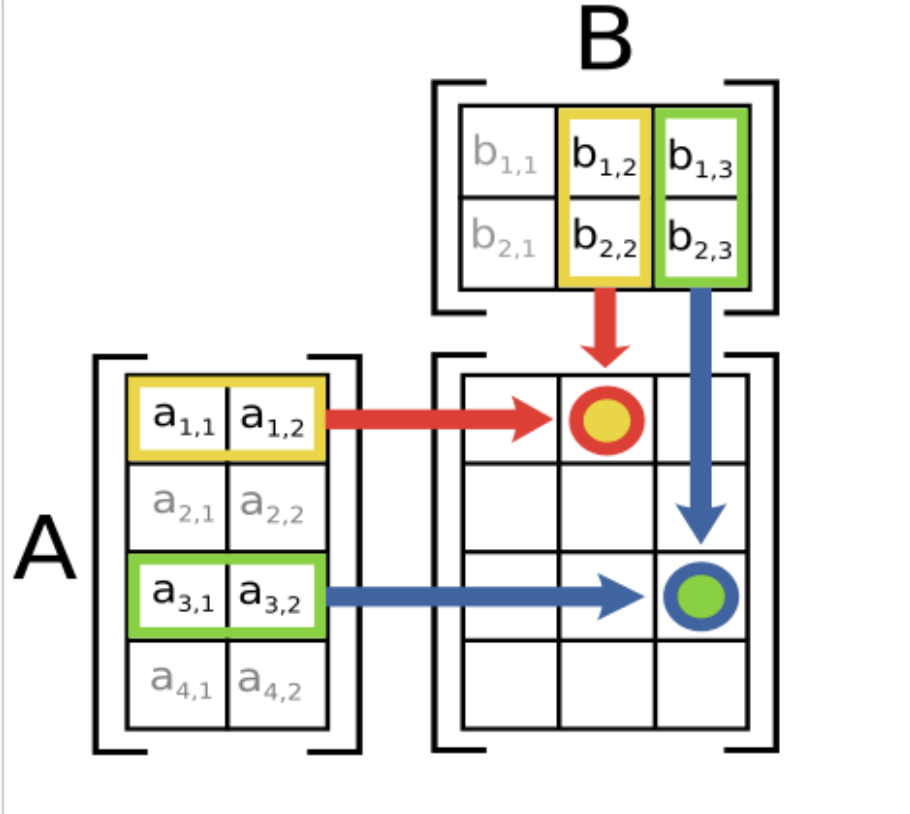

NumPy에서는 `@`로 행렬 곱을 계산한다. 모델에서 입력값에 가중치를 곱해 합산할 때 사용하는 계산이다.
`(3, 2) @ (2, 1)`의 결과는 `(3, 1)`이다.


In [ ]:
weights = np.array([[10], [20]])  # 각 입력값에 곱할 가중치
print("왼쪽 행렬:\n", matrix)
print("오른쪽 행렬:\n", weights)

result = matrix @ weights
print("행렬 곱 결과:\n", result)
print("모양:", matrix.shape, "@", weights.shape, "→", result.shape)
